# Utility bill payment form A/B test

The payments team ran an A/B test of a new utility bill payment form. The new form makes entering payment details simpler and has autofill. Group A saw the old form, group B saw the new one.

**Hypothesis:** autofilling payment details will increase the share of successful payments.

**Test:** 30 days, April 1-30, 2024. Users were split into groups, i.e. the split was by customers, not by payments.

**Funnel:** opened the form → entered payment details → confirmed the payment → successful payment.

**Key metric:** conversion from step 1 to step 4, i.e. from opening the form to a successful payment.

**Task:** decide whether to roll the new form out to all users.

Plan: load and clean the data, explore it (EDA), test the hypothesis, look at the effect by segment, draw charts and draw a conclusion.

## 1. Loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_confint
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

users = pd.read_excel('data/AB_test_synthetic.xlsx', sheet_name='Users')
pays = pd.read_excel('data/AB_test_synthetic.xlsx', sheet_name='Pays')

Let's see what is in the tables and whether there are missing values.

In [2]:
display(users.head(), pays.head())

,user_id,group,age,city,device_type
0,1001,A,34,Berlin,ios
1,1002,A,47,Berlin,ios
2,1003,A,28,Hamburg,android
3,1004,A,50,Hamburg,ios
4,1005,A,22,Other cities,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-15 19:20:00,NaT,NaT,NaT
1,5002,1001.0,A,2024-04-12 20:34:00,NaT,NaT,NaT
2,5003,1002.0,A,2024-04-14 02:15:00,2024-04-14 02:16:00,NaT,NaT
3,5004,1003.0,A,2024-04-11 21:46:00,2024-04-11 21:50:00,NaT,NaT
4,5005,1004.0,A,2024-04-29 17:32:00,2024-04-29 17:34:00,2024-04-29 17:39:00,2024-04-29 17:45:00


In [3]:
users.info()
pays.info()

<class 'pandas.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      1504 non-null   int64
 1   group        1503 non-null   str  
 2   age          1504 non-null   int64
 3   city         1503 non-null   str  
 4   device_type  1504 non-null   str  
dtypes: int64(2), str(3)
memory usage: 58.9 KB
<class 'pandas.DataFrame'>
RangeIndex: 2681 entries, 0 to 2680
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2681 non-null   int64         
 1   user_id          2680 non-null   float64       
 2   group            2681 non-null   str           
 3   step1_opened     2681 non-null   datetime64[us]
 4   step2_entered    2273 non-null   datetime64[us]
 5   step3_confirmed  1737 non-null   datetime64[us]
 6   step4_success    1531 non-null   datetime64[us]
dtypes

The users table has 1504 rows, the payments table has 2681. There are missing values in `group` and `city` in users and in `user_id` in payments. I don't treat missing values in `step2`-`step4` as errors: the person simply didn't reach that step.

There are also some odd records: ages that can't be real and ids that stand far apart from the rest of the series, and payments have such ids too.

In [4]:
display(users[(users['age'] < 14) | (users['age'] > 90)])
display(users[users['user_id'] > 5000])
display(pays[pays['payment_id'] > 90000])

,user_id,group,age,city,device_type
1501,9002,A,-5,Hamburg,android
1502,9003,B,150,Other cities,ios


,user_id,group,age,city,device_type
1500,9001,NaN,25,Berlin,ios
1501,9002,A,-5,Hamburg,android
1502,9003,B,150,Other cities,ios
1503,9004,A,30,NaN,android


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2678,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:32:00,2024-04-05 10:37:00,2024-04-05 10:38:00
2679,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:22:00,2024-04-08 14:27:00,2024-04-08 14:28:00
2680,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


Ages of -5 and 150 are clearly wrong. Users with ids 9001-9004 and payments 99001-99003 look like test or corrupted records: they are missing a group, a city or a user_id, and in one payment the group does not match the user's group. I'll remove all of these in the next step. I'll check duplicates separately.

In [5]:
print('Duplicate user_id:', users['user_id'].duplicated().sum())
print('Duplicate payment_id:', pays['payment_id'].duplicated().sum())

Duplicate user_id: 0
Duplicate payment_id: 0


No duplicates.

## 2. Data cleaning

I record every removal in the `log` list so that at the end I can show what was removed and why.

In [6]:
log = []

def drop(df, mask, sheet, reason):
    removed = df[mask]
    if len(removed):
        log.append({
            'sheet': sheet,
            'reason': reason,
            'rows removed': len(removed),
            'example ids': ', '.join(map(str, removed.iloc[:, 0].head(5))),
        })
    return df[~mask].copy()

### Users

I remove users with no group (it's unclear which variant they belong to), users whose age is outside 14-90 (data errors) and users with no city (I need the city for segments).

In [7]:
users_start = len(users)

users = drop(users, users['group'].isna(), 'Users', 'no A/B group')
users = drop(users, ~users['age'].between(14, 90), 'Users', 'age outside 14-90 (-5 and 150)')
users = drop(users, users['city'].isna(), 'Users', 'no city')

### Payments

I remove payments:
- without `user_id`, there is no one to link them to;
- of users I have already removed from the users table;
- where the group in the payment does not match the user's group. I trust the users table because the split into groups was done on it;
- with ids from 99000, which look like test records.

In [8]:
pays_start = len(pays)

pays = drop(pays, pays['user_id'].isna(), 'Pays', 'no user_id')
pays['user_id'] = pays['user_id'].astype(int)

pays = drop(pays, ~pays['user_id'].isin(users['user_id']), 'Pays', 'user was removed from the users table')

pays = pays.merge(users[['user_id', 'group']].rename(columns={'group': 'group_user'}), on='user_id')
pays = drop(pays, pays['group'] != pays['group_user'], 'Pays', "group in the payment does not match the user's group")
pays = pays.drop(columns='group_user')

pays = drop(pays, pays['payment_id'] >= 99000, 'Pays', 'test payment_id from 99000')

### What was removed in the end

In [9]:
log_df = pd.DataFrame(log)
display(log_df)

print('Users:', users_start, '->', len(users))
print('Payments:', pays_start, '->', len(pays))

,sheet,reason,rows removed,example ids
0,Users,no A/B group,1,9001
1,Users,age outside 14-90 (-5 and 150),2,"9002, 9003"
2,Users,no city,1,9004
3,Pays,no user_id,1,99003
4,Pays,user was removed from the users table,1,7678
5,Pays,group in the payment does not match the user's...,1,99002
6,Pays,test payment_id from 99000,1,99001


Users: 1504 -> 1500
Payments: 2681 -> 2677


In total I removed 8 rows: 4 users and 4 payments (0.15% of payments). The losses are tiny and should not affect the result. After cleaning, the groups have exactly 750 people each.

I save the cleaned data and the removal log, they will be useful for the report.

In [10]:
with pd.ExcelWriter('clean_synth_data.xlsx') as writer:
    users.to_excel(writer, sheet_name='Users', index=False)
    pays.to_excel(writer, sheet_name='Pays', index=False)
    log_df.to_excel(writer, sheet_name='synth_cleaning_log', index=False)

## 3. EDA

### 3.1 Group balance

I check that the groups turned out similar in device and city. If not, the difference in results could be attributed to something other than the form.

In [11]:
display(users['group'].value_counts())
display(pd.crosstab(users['group'], users['device_type'], normalize='index').round(3))
display(pd.crosstab(users['group'], users['city'], normalize='index').round(3))

group
A    750
B    750
Name: count, dtype: int64

device_type,android,ios
group,,
A,0.541,0.459
B,0.492,0.508


city,Berlin,Hamburg,Other cities
group,,,
A,0.384,0.259,0.357
B,0.408,0.265,0.327


In [12]:
for col in ['device_type', 'city']:
    p = chi2_contingency(pd.crosstab(users['group'], users[col]))[1]
    print(col, 'p-value =', round(p, 3))

device_type p-value = 0.063
city p-value = 0.44


The group sizes are equal, 750 each. City shares are close (p = 0.44). There is a small imbalance in device: group A has more android users (54% vs 49%). The difference is not significant (p = 0.063, above 0.05) but close to the threshold. Below, in the segments, I separately check that the effect is present on both android and ios, so that this imbalance doesn't spoil anything.

### 3.2 Age

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,750.0,32.5,7.6,20.0,27.0,33.0,38.0,60.0
B,750.0,32.6,7.6,20.0,27.0,33.0,38.0,55.0


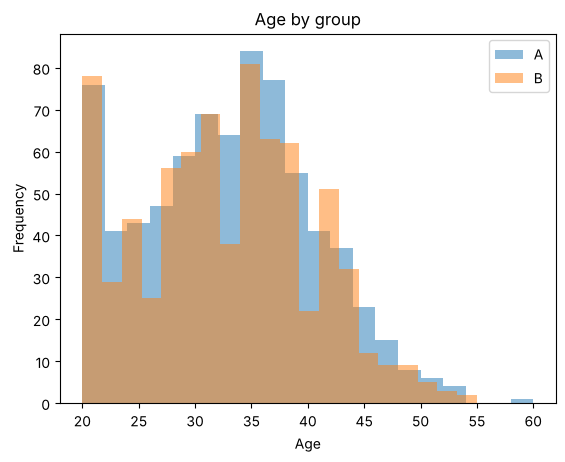

In [13]:
display(users.groupby('group')['age'].describe().round(1))

users.groupby('group')['age'].plot.hist(bins=20, alpha=0.5, legend=True, title='Age by group')
plt.xlabel('Age')
plt.show()

Age is the same in both groups: from 20 to 60, about 32.5 years on average. After cleaning there are no outliers.

### 3.3 Number of payments per user

In [14]:
payments_per_user = pays.groupby('user_id').size()
users['payments'] = users['user_id'].map(payments_per_user).fillna(0).astype(int)

display(users.groupby('group')['payments'].mean().round(2))
display(pd.crosstab(users['group'], users['payments'], normalize='index').round(3))
print('Users with no payments:', (users['payments'] == 0).sum())

group
A    1.75
B    1.82
Name: payments, dtype: float64

payments,1,2,3,4
group,,,,
A,0.536,0.239,0.169,0.056
B,0.465,0.317,0.145,0.072


Users with no payments: 0


Every user has at least one payment, four at most. On average there are 1.75 payments per user in group A and 1.82 in group B. Group B has somewhat more people with two payments (32% vs 24%). The difference is small, but I'll keep it in mind: it matters for the choice of metric.

It is important that one person can have several payments, while the groups were split by people.

### 3.4 Funnel

In [15]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
step_names = ['1. Opened the form', '2. Entered details', '3. Confirmed', '4. Successful payment']

funnel = pd.DataFrame(
    {g: [pays.loc[pays['group'] == g, s].notna().sum() for s in steps] for g in ['A', 'B']},
    index=step_names,
)
display(funnel)
display((funnel / funnel.iloc[0] * 100).round(1))

,A,B
1. Opened the form,1309,1368
2. Entered details,1060,1210
3. Confirmed,761,973
4. Successful payment,644,884


,A,B
1. Opened the form,100.0,100.0
2. Entered details,81.0,88.5
3. Confirmed,58.1,71.1
4. Successful payment,49.2,64.6


In [16]:
step_conv = (funnel / funnel.shift(1) * 100).round(1).iloc[1:]
step_conv.index = ['1 → 2', '2 → 3', '3 → 4']
display(step_conv)

,A,B
1 → 2,81.0,88.5
2 → 3,71.8,80.4
3 → 4,84.6,90.9


Counting by payments, 49.2% in group A and 64.6% in group B get from opening the form to a successful payment.

By step, the new form is better everywhere. The 2 → 3 conversion grew the most (about +8.6 pp), then 1 → 2 (+7.5 pp), and the last step 3 → 4 grew a bit less (+6.2 pp). For now this is just a comparison of numbers, I'll test significance below.

### 3.5 Time to payment

As an extra check I look at whether people started paying faster. I only take successful payments.

In [17]:
done = pays[pays['step4_success'].notna()].copy()
done['minutes'] = (done['step4_success'] - done['step1_opened']).dt.total_seconds() / 60

display(done.groupby('group')['minutes'].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
A,644.0,12.3,3.0,5.0,10.0,12.0,14.0,23.0
B,884.0,12.3,2.9,6.0,10.0,12.0,14.0,24.0


The time from opening the form to a successful payment is the same, about 12 minutes in both groups. So the gain is not in speed: more people simply get to the end.

## 4. Hypothesis testing

### 4.1 Which metric I use

One person can have several payments, and they resemble each other: if a person pays successfully, they will most likely pay successfully next time too. At the same time, the groups were split by people. If I counted every payment as a separate independent observation, the significance would be overstated.

So the main calculation is done by **users**: a user counts as successful if they had at least one successful payment.

But this metric has a downside: the more attempts a person has, the more chances to succeed, and group B has slightly more attempts (1.82 vs 1.75). So as a check I also look at conversion by **payments**, taking into account that payments are clustered by user.

I fix the significance level at 0.05 in advance, two-sided test.

In [18]:
pays['success'] = pays['step4_success'].notna().astype(int)
users['success'] = users['user_id'].map(pays.groupby('user_id')['success'].max()).fillna(0).astype(int)

summary = users.groupby('group')['success'].agg(['sum', 'count'])
summary.columns = ['successful', 'total']
summary['conversion, %'] = (summary['successful'] / summary['total'] * 100).round(2)
display(summary)

,successful,total,"conversion, %"
group,,,
A,494,750,65.87
B,603,750,80.40


### 4.2 Main test: comparing two proportions

A user's outcome is binary (had a successful payment or not), the groups are independent, 750 people in each. For this case a two-proportion z-test is appropriate.

In [19]:
cA, nA = summary.loc['A', ['successful', 'total']]
cB, nB = summary.loc['B', ['successful', 'total']]

z, p = proportions_ztest([cB, cA], [nB, nA])
low, high = confint_proportions_2indep(cB, nB, cA, nA)
diff = cB / nB - cA / nA

print(f'Conversion A: {cA / nA:.1%}, conversion B: {cB / nB:.1%}')
print(f'Difference: {diff * 100:.1f} pp (relative uplift {diff / (cA / nA):.1%})')
print(f'95% confidence interval of the difference: from {low * 100:.1f} to {high * 100:.1f} pp')
print(f'p-value = {p:.2g}')

Conversion A: 65.9%, conversion B: 80.4%
Difference: 14.5 pp (relative uplift 22.1%)
95% confidence interval of the difference: from 10.1 to 18.9 pp
p-value = 2.2e-10


Conversion grew from 65.9% to 80.4%, i.e. by 14.5 pp (22.1% in relative terms). The confidence interval from 10.1 to 18.9 pp does not include zero, and the p-value is far below 0.05. The difference is statistically significant.

### 4.3 Check by payments

Here I use logistic regression. It suits a yes/no outcome, and the `cov_type='cluster'` and `cov_kwds` parameters tell it that payments of the same user are dependent (clusters by `user_id`). This way the standard errors are computed correctly.

In [20]:
model = smf.logit('success ~ C(group)', data=pays).fit(
    cov_type='cluster', cov_kwds={'groups': pays['user_id']}, disp=False
)

display(pays.groupby('group')['success'].mean().round(3))
print('Odds ratio B vs A:', round(np.exp(model.params['C(group)[T.B]']), 2))
print('p-value =', f"{model.pvalues['C(group)[T.B]']:.2g}")

group
A    0.492
B    0.646
Name: success, dtype: float64

Odds ratio B vs A: 1.89
p-value = 3.9e-15


By payments the result is the same: the share of successful payments grew from 49.2% to 64.6%. An odds ratio of 1.89 means the odds of a successful payment with the new form are about 1.9 times higher. The p-value is again far below 0.05.

The two approaches give the same answer, so the difference in the number of attempts does not affect the conclusion.

## 5. Effect by segment

I look at whether the form works equally on different devices and in different cities. The main thing here is to find a segment where things got worse, it's important to know this before launch.

There are several segments, and the more comparisons, the higher the chance of getting a "significant" result by luck. To account for this I apply the Holm correction: it recalculates p-values for the number of comparisons.

In [21]:
def segment_effect(col, label):
    rows = []
    for name, part in users.groupby(col):
        a = part.loc[part['group'] == 'A', 'success']
        b = part.loc[part['group'] == 'B', 'success']
        low, high = confint_proportions_2indep(b.sum(), len(b), a.sum(), len(a))
        p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])[1]
        rows.append({
            'slice': label,
            'segment': name,
            'A, %': round(a.mean() * 100, 1),
            'B, %': round(b.mean() * 100, 1),
            'uplift, pp': round((b.mean() - a.mean()) * 100, 1),
            'CI low': round(low * 100, 1),
            'CI high': round(high * 100, 1),
            'p-value': p,
            'N in A': len(a),
            'N in B': len(b),
        })
    return pd.DataFrame(rows)

segments = pd.concat([
    segment_effect('device_type', 'device'),
    segment_effect('city', 'city'),
], ignore_index=True)
segments['p-value (Holm)'] = multipletests(segments['p-value'], method='holm')[1]

display(segments)

,slice,segment,"A, %","B, %","uplift, pp",CI low,CI high,p-value,N in A,N in B,p-value (Holm)
0,device,android,64.8,81.3,16.5,10.3,22.5,2.560240e-07,406,369,0.000001
1,device,ios,67.2,79.5,12.4,5.9,18.7,1.583379e-04,344,381,0.000475
2,city,Berlin,63.2,81.4,18.2,11.0,25.1,6.973168e-07,288,306,0.000003
3,city,Hamburg,67.0,82.9,15.9,7.4,24.2,2.690046e-04,194,199,0.000538
4,city,Other cities,67.9,77.1,9.2,1.5,16.8,1.956979e-02,268,245,0.019570


In all five segments the new form is better, there is no negative effect anywhere. In every segment both groups have more than 190 people, so there is enough data, and after the Holm correction all differences remain significant.

- **Device:** +16.5 pp on android, +12.4 pp on ios. The effect is similar, so the device imbalance from section 3.1 does not affect the result.
- **City:** +18.2 pp in Berlin, +15.9 pp in Hamburg, +9.2 pp in other cities. The effect is smallest in other cities, and the interval (from 1.5 to 16.8 pp) is closest to zero, so the launch there should be monitored more closely.

My segment analysis is exploratory: I base the decision on the overall result, and segments are there to make sure nothing got worse anywhere.

## 6. Charts

### 6.1 Funnel

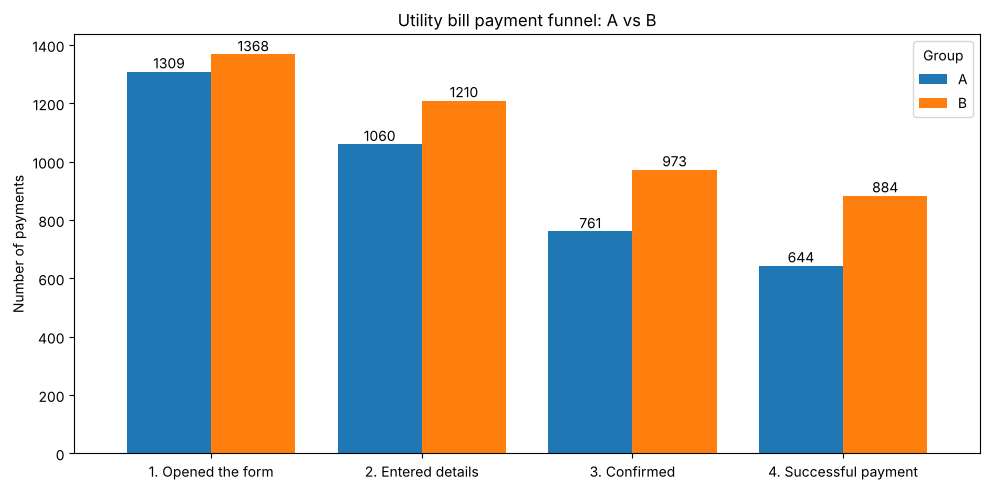

In [22]:
ax = funnel.plot.bar(rot=0, figsize=(10, 5), width=0.8, color=['tab:blue', 'tab:orange'])
for c in ax.containers:
    ax.bar_label(c)
ax.set_title('Utility bill payment funnel: A vs B')
ax.set_ylabel('Number of payments')
ax.legend(title='Group')
plt.tight_layout()
plt.savefig('viz_1_funnel.png', dpi=150)
plt.show()

The B bars are higher at every step, and the gap between the groups grows towards the end of the funnel.

### 6.2 Conversion to successful payment

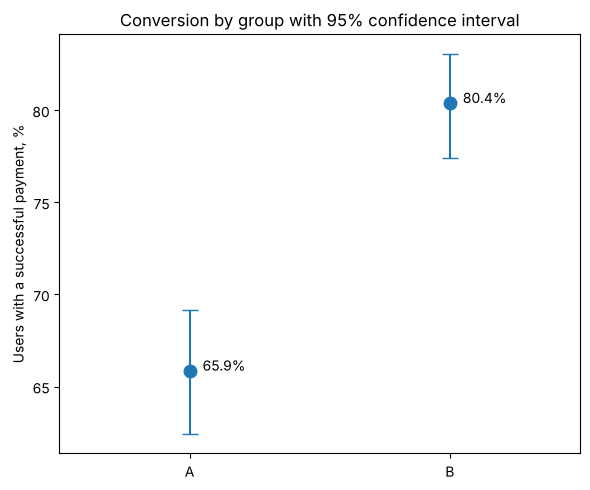

In [23]:
rows = []
for g, part in users.groupby('group'):
    k, n = part['success'].sum(), len(part)
    low, high = proportion_confint(k, n, method='wilson')
    rows.append((g, k / n * 100, low * 100, high * 100))
rates = pd.DataFrame(rows, columns=['group', 'rate', 'low', 'high'])

plt.figure(figsize=(6, 5))
plt.errorbar(rates['group'], rates['rate'],
             yerr=[rates['rate'] - rates['low'], rates['high'] - rates['rate']],
             fmt='o', capsize=6, markersize=9)
for i, r in rates.iterrows():
    plt.text(i + 0.05, r['rate'], f"{r['rate']:.1f}%")
plt.xlim(-0.5, 1.5)
plt.ylabel('Users with a successful payment, %')
plt.title('Conversion by group with 95% confidence interval')
plt.tight_layout()
plt.savefig('viz_2_conversion_ci.png', dpi=150)
plt.show()

The group intervals do not overlap, which is consistent with the test result.

### 6.3 Effect by segment

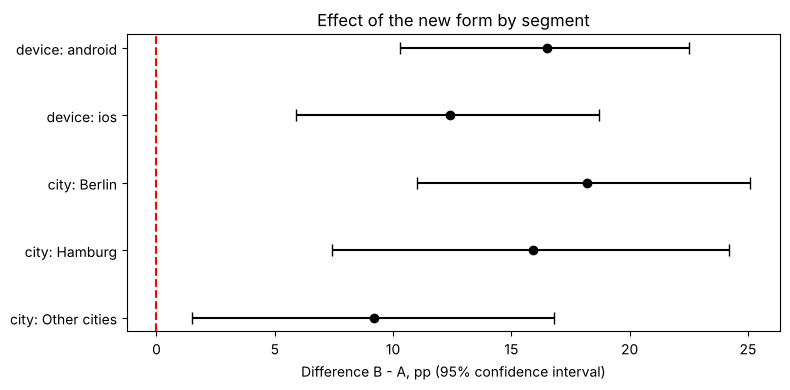

In [24]:
labels = segments['slice'] + ': ' + segments['segment']
effect = segments['uplift, pp']

plt.figure(figsize=(8, 4))
plt.errorbar(effect, range(len(segments)),
             xerr=[effect - segments['CI low'], segments['CI high'] - effect],
             fmt='o', capsize=4, color='black')
plt.axvline(0, color='red', linestyle='--')
plt.yticks(range(len(segments)), labels)
plt.gca().invert_yaxis()
plt.xlabel('Difference B - A, pp (95% confidence interval)')
plt.title('Effect of the new form by segment')
plt.tight_layout()
plt.savefig('viz_3_segment_uplift.png', dpi=150)
plt.show()

All points are to the right of the red zero line, and no interval crosses zero. The interval closest to zero is the one for other cities.

## 7. Conclusion and recommendation

**I recommend rolling out the new form to all users, but in stages.**

Why:

- Conversion to a successful payment among users grew from 65.9% to 80.4% (+14.5 pp, 95% CI from 10.1 to 18.9 pp, p < 0.001). By payments it is the same: from 49.2% to 64.6%.
- The form is better at every step of the funnel, most of all at the transition from entering details to confirmation.
- There is no negative effect on android, on ios, or in any of the cities.
- I cleaned the data (removed 8 rows, 0.15% of payments), this does not affect the result. The groups turned out comparable.

What to watch:

- In other cities the effect is noticeably weaker (+9.2 pp) than in Berlin (+18.2 pp).
- The data has no payment errors, refunds or support tickets. Autofill may insert wrong payment details, so these metrics should be monitored during the launch.
- The test ran for 30 days. I did not check whether the effect is stable week by week, so a novelty effect cannot be fully ruled out.
- Time to payment did not change, so the gain is specifically in the share of people who reach the end.

I suggest rolling out to 10% of users, then 50%, then 100%, and at each stage watching conversion and payment errors.